# 機械学習によるコーパス品質管理と能動学習

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch5_corpus_quality.ipynb)

書籍 第5章「言語資源のつくり方」（5-4-3 コーパス作成の品質管理）に対応する演習ノートブックです。
[フレーズ分類ラベルアノテーションと作業者間一致率](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch5_annotation.ipynb) で扱った宿泊レビューフレーズデータ（`phrase-annotation.csv`、100件：仕様改訂前の第1ラウンド 50件 + 仕様改訂後の第2ラウンド 50件）を用い、構築したコーパスを機械学習モデルで検証・効率化する手法を体験します。

1. 仕様改善前のラベル vs 確定ラベルでの分類器比較 (5-4-3)
2. 学習曲線による必要データ量の見積もり
3. モデルの予測確率を使ったアノテーションミスの発見 (5-4-3)
4. 能動学習（不確実性サンプリング）によるアノテーション効率化

## 準備とデータの読み込み

第5章のサンプルデータ `phrase-annotation.csv` をダウンロードし、第1ラウンド（`r1`、50件）と第2ラウンド（`r2`、50件）に分けて読み込みます。

In [1]:
!pip install -q matplotlib-fontja
!curl -fsSLO https://raw.githubusercontent.com/mamorlis/nlpbook/refs/heads/main/misc/phrase-annotation.csv

In [2]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline

df = pd.read_csv("phrase-annotation.csv").fillna({"コメント": ""})
r1 = df[df["ラウンド"] == 1].copy()
r2 = df[df["ラウンド"] == 2].copy()

print(f"総件数: {len(df)} 件（第1ラウンド: {len(r1)} 件 / 第2ラウンド: {len(r2)} 件）")
print("3値評価『極性ラベル』の分布:", df["極性ラベル"].value_counts().to_dict())

総件数: 100 件（第1ラウンド: 50 件 / 第2ラウンド: 50 件）
3値評価『極性ラベル』の分布: {'pos': 38, 'neu': 32, 'neg': 30}


---

## 1. 仕様改善前のラベル vs 確定ラベルでの分類器比較 (5-4-3)

書籍 5-4-3 にあるように、作成したデータで実際に分類器を動かして品質を検証します。
第1ラウンド（50件）の「仕様改訂前（作業者A / 作業者B）」のラベルで学習した分類器と、「すり合わせ後の確定ラベル（`極性ラベル`）」で学習した分類器を、未知の第2ラウンド（50件）で比較します。

In [3]:
results = []
for label_name, col in [
    ("作業者A（改訂前・個人）", "作業者A"),
    ("作業者B（改訂前・個人）", "作業者B"),
    ("確定ラベル（仕様調整後）", "極性ラベル"),
]:
    clf = make_pipeline(
        TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3)),
        LogisticRegression(max_iter=1000, C=2.0),
    )
    clf.fit(r1["フレーズ"], r1[col])
    pred = clf.predict(r2["フレーズ"])
    results.append({
        "訓練ラベル": label_name,
        "テスト正解率": round(accuracy_score(r2["極性ラベル"], pred), 3),
        "テスト macro-F1": round(f1_score(r2["極性ラベル"], pred, average="macro"), 3),
    })

pd.DataFrame(results)

,訓練ラベル,テスト正解率,テスト macro-F1
0,作業者A（改訂前・個人）,0.44,0.303
1,作業者B（改訂前・個人）,0.54,0.479
2,確定ラベル（仕様調整後）,0.70,0.687


作業者の解釈が揃っていないノイジーなラベルで学習するよりも、仕様をすり合わせて一貫性を持たせた確定ラベルで学習したほうが、未知データへの汎化性能が大きく向上することがわかります。

---

## 2. 学習曲線による必要データ量の見積もり

ある程度の品質が確保できたら、学習データの分量を変えながら性能推移（学習曲線）を確認します。これにより、目標精度に達するためにあと何件のアノテーションが必要かを見積もることができます。

In [4]:
from sklearn.model_selection import StratifiedKFold, learning_curve

clf_lc = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3)),
    LogisticRegression(max_iter=1000, C=3.0),
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    clf_lc,
    df["フレーズ"],
    df["極性ラベル"],
    cv=cv,
    train_sizes=[0.25, 0.5, 0.75, 1.0],
    scoring="f1_macro",
    shuffle=True,
    random_state=42,
)

lc_df = pd.DataFrame({
    "訓練データ数": train_sizes,
    "訓練 macro-F1": train_scores.mean(axis=1).round(3),
    "検証 macro-F1（平均）": val_scores.mean(axis=1).round(3),
    "検証 macro-F1（標準偏差）": val_scores.std(axis=1).round(3),
})
lc_df

,訓練データ数,訓練 macro-F1,検証 macro-F1（平均）,検証 macro-F1（標準偏差）
0,20,1.0,0.424,0.152
1,40,1.0,0.486,0.158
2,60,1.0,0.569,0.059
3,80,1.0,0.637,0.086


---

## 3. モデルの予測確率を使ったアノテーションミスの発見 (5-4-3)

5-4-3 で述べられているとおり、作成したデータで学習した分類器の予測結果を確認することで、**ラベルの付与間違いの候補** を絞り込むことができます。

ここでは確定ラベルのコピーに対して、あえて 3 件だけ誤ったラベル (ID 9, 49, 65) を混入させ、交差検証による予測確率 (`cross_val_predict`) と付与ラベルが強く食い違う事例を上位から表示してみます。

In [5]:
from sklearn.model_selection import cross_val_predict

# デモ用にあえて 3 件だけ人間が押し間違えたラベルを混ぜる
slip_ids = [9, 49, 65]
slip_map = {"pos": "neg", "neg": "pos", "neu": "pos"}
labels_with_slips = df["極性ラベル"].copy()
for fid in slip_ids:
    mask = df["フレーズID"] == fid
    labels_with_slips.loc[mask] = labels_with_slips.loc[mask].map(slip_map)

clf_err = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3)),
    LogisticRegression(max_iter=1000, C=10.0),
)
oof_probs = cross_val_predict(clf_err, df["フレーズ"], labels_with_slips, cv=cv, method="predict_proba")
classes = ["neg", "neu", "pos"]
class_to_idx = {c: i for i, c in enumerate(classes)}

p_assigned = np.array([oof_probs[i, class_to_idx[lbl]] for i, lbl in enumerate(labels_with_slips)])
p_max = oof_probs.max(axis=1)

audit_df = pd.DataFrame({
    "フレーズID": df["フレーズID"],
    "付与ラベル": labels_with_slips,
    "モデル予測": [classes[i] for i in oof_probs.argmax(axis=1)],
    "本来のラベル": df["極性ラベル"],
    "確信度差": (p_max - p_assigned).round(3),
    "ミス混入対象": df["フレーズID"].isin(slip_ids),
    "フレーズ": df["フレーズ"],
})

audit_df.sort_values("確信度差", ascending=False).head(8)

,フレーズID,付与ラベル,モデル予測,本来のラベル,確信度差,ミス混入対象,フレーズ
8,9,pos,neu,neu,0.925,True,チェック イン 手続き を
81,82,pos,neu,pos,0.820,False,毎回 の リピート 利用
64,65,pos,neg,neg,0.682,True,シャワー の 温度 調節 が 安定 せ ず 突然 水 に なっ て 困っ た
44,45,neu,pos,neu,0.676,False,全 客室 に 加湿 空気 清浄 機 を 完備 し て い て
69,70,neu,pos,neu,0.581,False,自動 チェック イン 機 に よる 非 対面 手続き
48,49,neg,pos,pos,0.563,True,次 の 東京 出張 で も 是非 リピート し た い と 思 い ま す
65,66,neu,pos,neu,0.460,False,建物 １ 階 に カフェ と 薬局 が 入っ て い ま す
2,3,neu,neg,neu,0.460,False,駅 の 近く に 飲食店 が 多 く あ る の が


---

## 4. 能動学習（不確実性サンプリング）によるアノテーション効率化

人手でデータにラベルを付けるコストは高いため、未ラベルのプールからランダムに事例を選ぶのではなく、現在のモデルが**予測に最も迷っている事例**を優先的に選んでアノテーションする**能動学習 (Active Learning)** が広く使われます。

ここでは、予測確率の最大値から算出する**最小確信度 (Least Confidence) に基づく不確実性サンプリング**を実装します。

$$u(x) = 1 - \max_{c} P(c \mid x)$$

確定ラベル付き 100 件を用い、第 2 節と同じ 5 分割層化交差検証の各分割（訓練・プール候補 80 件、テスト 20 件）において、初期ラベル済みシード 18 件から未ラベルプール 62 件に対してバッチサイズ 5 件ずつラベル数 68 件まで増やしながら、**ランダムサンプリング**と**不確実性サンプリング**のテスト Accuracy・Macro-F1 の 5 分割平均を比較します（分類器は第 1 節と同じ文字 n-gram TF-IDF + ロジスティック回帰 `C=2.0`）。

,ラベル済み件数,ランダム Accuracy,不確実性 Accuracy,ランダム Macro-F1,不確実性 Macro-F1,Macro-F1 改善
0,18,0.42,0.42,0.273,0.273,0.000
1,23,0.45,0.64,0.341,0.587,0.246
2,28,0.46,0.63,0.375,0.589,0.214
3,33,0.47,0.62,0.391,0.588,0.196
4,38,0.49,0.64,0.416,0.576,0.161
5,43,0.55,0.62,0.500,0.595,0.095
6,48,0.56,0.65,0.516,0.640,0.124
7,53,0.59,0.64,0.540,0.625,0.085
8,58,0.59,0.69,0.542,0.686,0.144
9,63,0.60,0.68,0.560,0.667,0.107


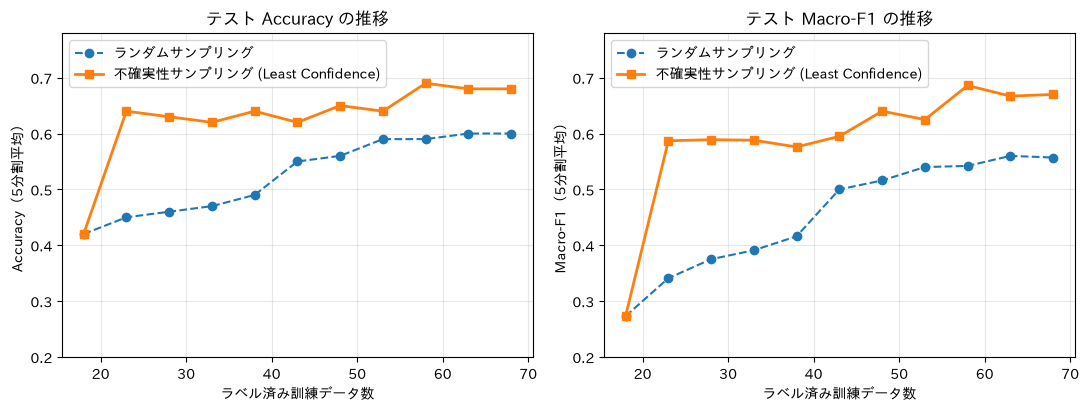

In [6]:
import matplotlib.pyplot as plt
import matplotlib_fontja  # noqa: F401
from sklearn.model_selection import StratifiedShuffleSplit

plt.rcParams["axes.unicode_minus"] = False

X_al = df["フレーズ"].to_numpy()
y_al = df["極性ラベル"].to_numpy()

n_seed = 18
batch_size = 5
max_labeled = 68

scores = {
    mode: {b: {"acc": [], "f1": []} for b in range(n_seed, max_labeled + 1, batch_size)}
    for mode in ("random", "uncertainty")
}

for fold, (train_pool_idx, test_idx) in enumerate(cv.split(X_al, y_al)):
    X_tp, y_tp = X_al[train_pool_idx], y_al[train_pool_idx]
    X_te, y_te = X_al[test_idx], y_al[test_idx]

    sss = StratifiedShuffleSplit(n_splits=1, train_size=n_seed, random_state=100 + fold)
    seed_rel, pool_rel = next(sss.split(X_tp, y_tp))

    for mode in ("random", "uncertainty"):
        labeled = list(seed_rel)
        pool = list(pool_rel)
        rng_al = np.random.default_rng(42 + fold)

        while len(labeled) <= max_labeled:
            clf_al = make_pipeline(
                TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3)),
                LogisticRegression(max_iter=1000, C=2.0),
            )
            clf_al.fit(X_tp[labeled], y_tp[labeled])
            pred_al = clf_al.predict(X_te)

            b = len(labeled)
            scores[mode][b]["acc"].append(accuracy_score(y_te, pred_al))
            scores[mode][b]["f1"].append(f1_score(y_te, pred_al, average="macro"))

            if len(labeled) + batch_size > max_labeled or len(pool) < batch_size:
                break

            if mode == "random":
                chosen_pos = rng_al.choice(len(pool), size=batch_size, replace=False)
            else:
                probs = clf_al.predict_proba(X_tp[pool])
                uncertainty = 1.0 - probs.max(axis=1)
                chosen_pos = np.argsort(uncertainty)[::-1][:batch_size]

            chosen = [pool[i] for i in chosen_pos]
            chosen_set = set(chosen)
            labeled.extend(chosen)
            pool = [idx for idx in pool if idx not in chosen_set]

budgets = sorted(scores["random"].keys())
al_rows = []
for b in budgets:
    r_acc = float(np.mean(scores["random"][b]["acc"]))
    u_acc = float(np.mean(scores["uncertainty"][b]["acc"]))
    r_f1 = float(np.mean(scores["random"][b]["f1"]))
    u_f1 = float(np.mean(scores["uncertainty"][b]["f1"]))
    al_rows.append({
        "ラベル済み件数": b,
        "ランダム Accuracy": round(r_acc, 3),
        "不確実性 Accuracy": round(u_acc, 3),
        "ランダム Macro-F1": round(r_f1, 3),
        "不確実性 Macro-F1": round(u_f1, 3),
        "Macro-F1 改善": round(u_f1 - r_f1, 3),
    })

al_df = pd.DataFrame(al_rows)
display(al_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
for ax, col_r, col_u, ylabel, title in [
    (axes[0], "ランダム Accuracy", "不確実性 Accuracy", "Accuracy（5分割平均）", "テスト Accuracy の推移"),
    (axes[1], "ランダム Macro-F1", "不確実性 Macro-F1", "Macro-F1（5分割平均）", "テスト Macro-F1 の推移"),
]:
    ax.plot(al_df["ラベル済み件数"], al_df[col_r], marker="o", linestyle="--", label="ランダムサンプリング")
    ax.plot(al_df["ラベル済み件数"], al_df[col_u], marker="s", linewidth=2, label="不確実性サンプリング (Least Confidence)")
    ax.set_xlabel("ラベル済み訓練データ数")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_ylim(0.2, 0.78)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

表と学習曲線から、初期シード 18 件の後に不確実性サンプリングでわずか 5〜10 件（合計 23〜28 件）を優先的にラベル付けした段階で、ランダムサンプリングで 68 件近くラベル付けした場合と同等以上の精度（Accuracy・Macro-F1）に到達していることがわかります。モデルが迷う境界事例を先に人手で確認することで、同じ目標精度を少ないアノテーション件数で達成できます。

このように、**「アノテーション仕様の整備・一致率検証（[フレーズ分類ラベルアノテーションと作業者間一致率](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch5_annotation.ipynb)） → 分類器による品質点検・学習曲線での必要量見積もり → 能動学習による効率的なデータ追加」** のサイクルを回すことで、高品質な言語資源を効率よく継続的に構築できます。